In [262]:
import tensorflow as tf
import matplotlib.pyplot as pt
from sklearn import datasets
import pandas as pd
import numpy as np
from tensorflow.keras.layers import Flatten

In [263]:
# !pip install huggingface_hub

In [264]:
# from datasets import load_dataset

# ds = load_dataset("moonworks/lunara-art-eval")

In [265]:
# from dotenv import load_dotenv
# load_dotenv()

In [266]:
(X_train, y_train), (X_test, y_test) = tf.keras.datasets.cifar10.load_data()


In [267]:
np.unique(y_train)

array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype=uint8)

In [268]:
print(X_train.shape)
print(y_train.shape)

print(X_test.shape)
print(y_test.shape)


(50000, 32, 32, 3)
(50000, 1)
(10000, 32, 32, 3)
(10000, 1)


In [269]:
X_train[0].shape

(32, 32, 3)

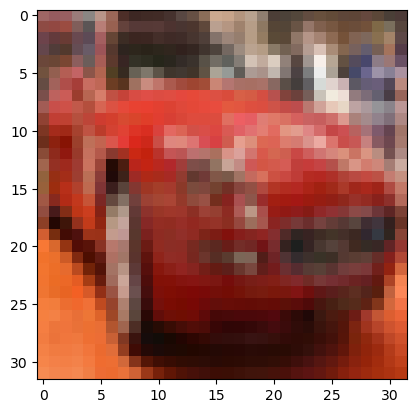

In [270]:
pt.imshow(X_train[5].reshape(32, -1, 3))

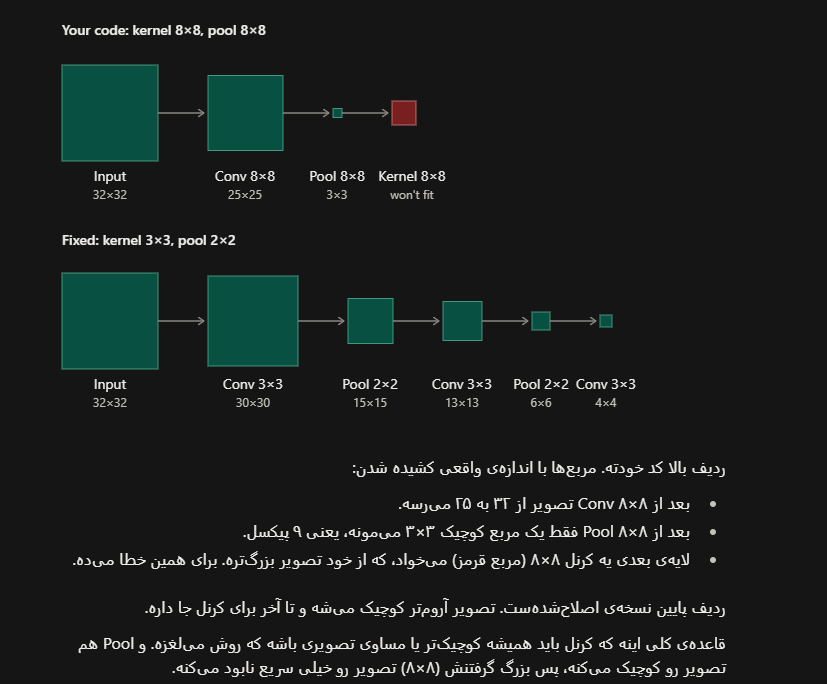

<div dir=rtl>
با این فرمول:

خروجی = ورودی − کرنل + 1

برای Conv ۸×۸ روی تصویر ۳۲×۳۲:

۳۲ − ۸ + ۱ = ۲۵

</div>

In [271]:
X_train = X_train.astype('float32')
X_test = X_test.astype('float32')

X_train = X_train / 255
X_test = X_test / 255

In [272]:
X_train = X_train.reshape(-1,32,32,3)
X_test = X_test.reshape(-1,32,32,3)

In [273]:
print(X_train.shape)
print(y_train.shape)

print(X_test.shape)
print(y_test.shape)

(50000, 32, 32, 3)
(50000, 1)
(10000, 32, 32, 3)
(10000, 1)


In [239]:
model = tf.keras.models.Sequential()
model.add(tf.keras.Input(shape=(32, 32, 3)))
model.add(tf.keras.layers.Conv2D(8, (3, 3), activation="relu"))
model.add(tf.keras.layers.Dropout(0.2))
model.add(tf.keras.layers.MaxPool2D((2, 2))) # اندازه عکس رو نصف میکنه

model.add(tf.keras.layers.Conv2D(16, (3, 3), activation="relu"))
model.add(tf.keras.layers.MaxPool2D((2, 2)))
model.add(tf.keras.layers.Dropout(0.2))
model.add(tf.keras.layers.Conv2D(32, (3, 3), activation="relu"))

model.add(tf.keras.layers.Flatten())
model.add(tf.keras.layers.Dense(64, activation="relu"))
model.add(tf.keras.layers.Dropout(0.2))
model.add(tf.keras.layers.Dense(128))
model.add(tf.keras.layers.Dropout(0.5))
model.add(tf.keras.layers.Dense(256))
model.add(tf.keras.layers.Dense(10,activation='softmax'))

In [240]:
model.summary()

Model: "sequential_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_36 (Conv2D)              │ (None, 30, 30, 8)      │           224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_28 (Dropout)            │ (None, 30, 30, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_24 (MaxPooling2D) │ (None, 15, 15, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_37 (Conv2D)              │ (None, 13, 13, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_25 (MaxPooling2D) │ (None, 6, 6, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_29 (Dropout)            │ (None, 6, 6, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_38 (Conv2D)              │ (None, 4, 4, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_12 (Flatten)            │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 64)             │        32,832 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_30 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_49 (Dense)                │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_31 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_50 (Dense)                │ (None, 256)            │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_51 (Dense)                │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 82,778 (323.35 KB)

 Trainable params: 82,778 (323.35 KB)

 Non-trainable params: 0 (0.00 B)

In [241]:
model.compile(loss= tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True) , optimizer='adam' , metrics= ['accuracy'])

In [242]:
hist = model.fit(X_train,y_train,epochs=200,batch_size=64,validation_split=0.2)

Epoch 1/200
625/625 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.3217 - loss: 1.8268 - val_accuracy: 0.4548 - val_loss: 1.5209
Epoch 2/200
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.4323 - loss: 1.5542 - val_accuracy: 0.4958 - val_loss: 1.4043
Epoch 3/200
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.4766 - loss: 1.4497 - val_accuracy: 0.4878 - val_loss: 1.3953
Epoch 4/200
625/625 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.5039 - loss: 1.3836 - val_accuracy: 0.5441 - val_loss: 1.2894
Epoch 5/200
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5226 - loss: 1.3303 - val_accuracy: 0.5209 - val_loss: 1.3251
Epoch 6/200
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5373 - loss: 1.2999 - val_accuracy: 0.5375 - val_loss: 1.2669
Epoch 7/200
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5528 - loss: 1.2627 - val_accuracy: 0.5847 - val_loss: 1.1638
Epoch 8/200
625/625 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.5634 - loss: 1.2312 - val_accu

KeyboardInterrupt: 

In [ ]:
hist.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

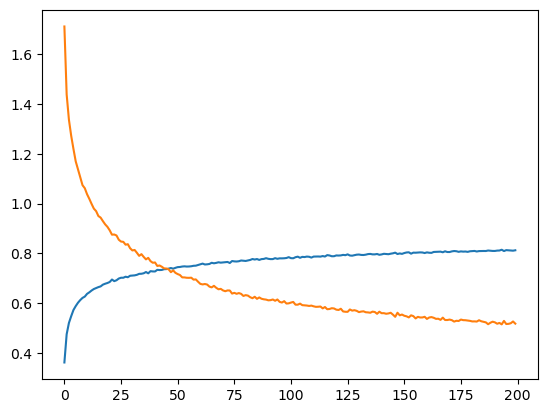

In [ ]:
pt.plot(hist.history['accuracy'])
pt.plot(hist.history['loss'])

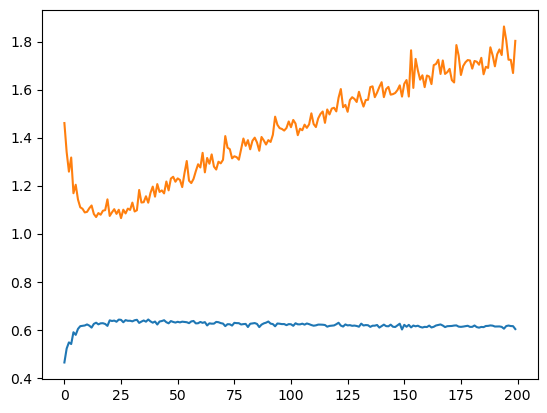

In [ ]:
pt.plot(hist.history['val_accuracy'])
pt.plot(hist.history['val_loss'])